# Vanishing Gradient Problem in ANN 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [2]:
X, y = make_moons(n_samples=250, noise=0.05, random_state=42)

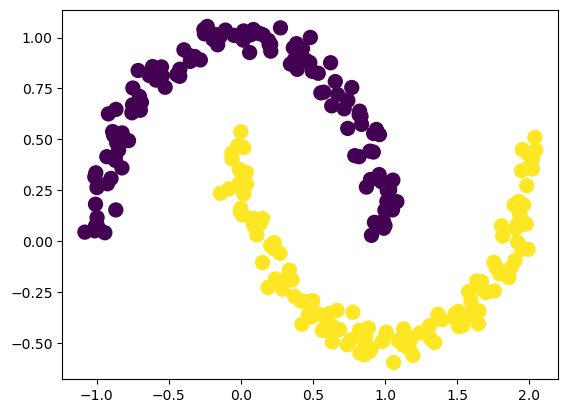

In [3]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=100)
plt.show()

In [4]:
model = Sequential()

model.add(Dense(10, activation="sigmoid", input_dim=2))
model.add(Dense(10, activation="sigmoid"))
model.add(Dense(10, activation="sigmoid"))
model.add(Dense(1, activation="sigmoid"))

/home/ipartzix/miniconda3/envs/MLE/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

In [6]:
model.get_weights()[0]

array([[ 0.40241152, -0.23775238,  0.07467312,  0.3473665 ,  0.6298241 ,
        -0.69412977,  0.38101596,  0.50545925,  0.02187943, -0.11890095],
       [-0.03006536, -0.14825743, -0.46787536, -0.60023737,  0.09517616,
        -0.43968874,  0.1323089 , -0.57769656, -0.02339453, -0.6750195 ]],
      dtype=float32)

In [7]:
old_weights = model.get_weights()[0]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [9]:
model.fit(X_train, y_train, epochs=100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.4900 - loss: 0.7030
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4900 - loss: 0.6998
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4900 - loss: 0.6974
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4900 - loss: 0.6961
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4900 - loss: 0.6947
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4900 - loss: 0.6938
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4900 - loss: 0.6936
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4900 - loss: 0.6929
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4900 - loss: 0.6926
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4900 - loss: 0.6924
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4900 - loss: 0.6922
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4900 - lo

In [10]:
new_weights = model.get_weights()[0]

In [11]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [12]:
gradient = (old_weights - new_weights) / 0.001
percent_change = abs(100 * (old_weights - new_weights) / old_weights)

In [13]:
gradient

array([[  668.6034 ,   718.30035,  -802.18427,   129.66782,  -498.88806,
          619.6615 ,  -645.28265,  -601.97284,   767.4912 ,   347.9433 ],
       [ -922.8751 , -1090.5309 ,  1192.1598 ,   -83.31835,   902.0435 ,
        -1031.1145 ,  1018.6908 ,  1095.8342 , -1057.3499 ,  -756.3115 ]],
      dtype=float32)

In [14]:
percent_change

array([[ 166.14919 ,  302.12122 , 1074.2612  ,   37.32882 ,   79.2107  ,
          89.27171 ,  169.35844 ,  119.094246, 3507.8203  ,  292.6329  ],
       [3069.5632  ,  735.5658  ,  254.80287 ,   13.880899,  947.76215 ,
         234.51012 ,  769.9337  ,  189.69029 , 4519.647   ,  112.04292 ]],
      dtype=float32)

In [15]:
old_weights

array([[ 0.40241152, -0.23775238,  0.07467312,  0.3473665 ,  0.6298241 ,
        -0.69412977,  0.38101596,  0.50545925,  0.02187943, -0.11890095],
       [-0.03006536, -0.14825743, -0.46787536, -0.60023737,  0.09517616,
        -0.43968874,  0.1323089 , -0.57769656, -0.02339453, -0.6750195 ]],
      dtype=float32)

In [16]:
new_weights

array([[-0.2661919 , -0.9560528 ,  0.8768574 ,  0.2176987 ,  1.1287122 ,
        -1.3137913 ,  1.0262986 ,  1.1074321 , -0.7456118 , -0.46684426],
       [ 0.8928098 ,  0.94227356, -1.6600353 , -0.516919  , -0.8068674 ,
         0.59142584, -0.88638186, -1.6735308 ,  1.0339553 ,  0.08129206]],
      dtype=float32)

In [17]:
model = Sequential()

model.add(Dense(10, activation="relu", input_dim=2))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(10, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

In [18]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

In [19]:
old_weights = model.get_weights()[0]    

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [21]:
model.fit(X_train, y_train, epochs=100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.4850 - loss: 0.6930
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5200 - loss: 0.6920
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5250 - loss: 0.6904
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7750 - loss: 0.6884
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8300 - loss: 0.6854
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8550 - loss: 0.6814
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8700 - loss: 0.6750
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8600 - loss: 0.6655
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8600 - loss: 0.6508
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8600 - loss: 0.6292
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8600 - loss: 0.5976
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8600 - lo

In [22]:
new_weights = model.get_weights()[0]

In [23]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [24]:
gradient = (old_weights - new_weights) / 0.001
percent_change = abs(100 * (old_weights - new_weights) / old_weights) 

In [25]:
gradient

array([[-8.2552426e-02,  4.9015541e+01, -1.5831248e+02,  4.3121246e+01,
         7.3020454e+01, -8.3151787e+01, -1.6905850e+02, -9.4651726e+01,
        -4.8995285e+01, -7.1289772e+01],
       [-1.9847155e+01, -6.6466988e+01,  1.0362821e+02,  8.0426865e+01,
         2.9244303e+01, -5.2947517e+01,  1.2547081e+02, -7.1489357e+01,
         1.6843184e+02, -6.9327888e+01]], dtype=float32)

In [26]:
percent_change

array([[1.28672365e-02, 3.38327827e+01, 2.40226593e+01, 4.94082909e+01,
        3.54038048e+01, 1.64750290e+01, 4.90880661e+01, 8.55814743e+01,
        3.28290825e+01, 1.08973970e+01],
       [2.90883088e+00, 1.54748402e+01, 2.73037014e+01, 4.08231262e+02,
        2.02510834e+01, 8.93394089e+00, 3.42455826e+01, 2.79373150e+01,
        5.03199501e+01, 1.19192915e+01]], dtype=float32)

In [27]:
old_weights

array([[-0.6415708 ,  0.14487588,  0.6590132 , -0.08727533, -0.20625031,
        -0.5047141 , -0.3443984 , -0.11059839, -0.14924353, -0.6541909 ],
       [ 0.68230695,  0.4295165 ,  0.37953907,  0.0197013 , -0.14440858,
         0.59265584, -0.3663854 ,  0.25589204, -0.33472183,  0.58164436]],
      dtype=float32)

In [28]:
new_weights

array([[-0.64148825,  0.09586034,  0.8173257 , -0.13039657, -0.27927077,
        -0.42156228, -0.17533989, -0.01594666, -0.10024825, -0.5829011 ],
       [ 0.7021541 ,  0.49598348,  0.27591085, -0.06072557, -0.17365289,
         0.64560336, -0.49185622,  0.3273814 , -0.5031537 ,  0.65097225]],
      dtype=float32)